# Model Building — Phishing Website Detector

**Projeto:** Deteção de Websites de Phishing através de Machine Learning  
**Fase:** Model Building (CRISP-ML(Q))  
**Curso:** Inteligência Artificial Aplicada à Cibersegurança  
**Data:** Setembro de 2026

Nesta fase são desenvolvidos e comparados quatro modelos de classificação supervisionada:
1. Logistic Regression (baseline)
2. Decision Tree
3. Random Forest
4. XGBoost (obrigatório)

**Referência:** [GeeksforGeeks Machine Learning Tutorial](https://www.geeksforgeeks.org/machine-learning/machine-learning-tutorial/) — Module 6 (Supervised Learning, Ensemble Learning, XGBoost) e Module 7 (Confusion Matrix, Precision, Recall, F1-Score, AUC-ROC, Cross-validation).

## Preparação do ambiente

In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

PASTA_PROJETO = Path.cwd().parent
sys.path.insert(0, str(PASTA_PROJETO / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from model_utils import (
    carregar_dataset_preparado,
    separar_features_target,
    dividir_treino_teste,
    criar_logistic_regression,
    criar_decision_tree,
    criar_random_forest,
    criar_xgboost,
    treinar_modelo,
    prever,
    prever_probabilidades,
    avaliar_modelo,
    cross_validation,
    comparar_treino_teste,
    comparar_modelos,
    importancia_features,
    grafico_matriz_confusao,
    grafico_comparacao,
    grafico_curvas_roc,
    grafico_curvas_pr,
    grafico_feature_importance,
)

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 1. Importação do dataset preparado

In [2]:
df = carregar_dataset_preparado("phishing_prepared.csv")
df.head()

Dataset preparado carregado: 5721 registos × 31 colunas


,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,-1,0,-1,1,-1,-1,1,1,-1,1,...,1,1,1,1,1,-1,1,-1,-1,1


## 2. Separação de features e target

In [3]:
X, y = separar_features_target(df, "class")

# Mapear classes: -1 -> 0 (phishing), 1 -> 1 (legítimo)
y = y.map({-1: 0, 1: 1})

print("Distribuição das classes:")
print(y.value_counts())

Features (X): (5721, 30)
Target (y): (5721,)
Distribuição das classes:
class
0    2955
1    2766
Name: count, dtype: int64


## 3. Divisão treino e teste

In [4]:
X_train, X_test, y_train, y_test = dividir_treino_teste(X, y)
nomes_features = X.columns.tolist()

Treino: X_train=(4576, 30), y_train=(4576,)
Teste:  X_test=(1145, 30), y_test=(1145,)


## 4. Criação dos modelos

In [5]:
logistic_regression = criar_logistic_regression()
decision_tree = criar_decision_tree()
random_forest = criar_random_forest()
xgboost = criar_xgboost()

modelos = [
    ("Logistic Regression", logistic_regression),
    ("Decision Tree", decision_tree),
    ("Random Forest", random_forest),
    ("XGBoost", xgboost),
]

for nome, modelo in modelos:
    print(f"  • {nome}")

  • Logistic Regression
  • Decision Tree
  • Random Forest
  • XGBoost


## 5. Treino dos modelos

In [6]:
for nome, modelo in modelos:
    treinar_modelo(modelo, X_train, y_train)
    print(f"  • {nome} treinado.")

  • Logistic Regression treinado.
  • Decision Tree treinado.


  • Random Forest treinado.
  • XGBoost treinado.


## 6. Previsões e avaliação no conjunto de teste

In [7]:
resultados = []

for nome, modelo in modelos:
    y_pred = prever(modelo, X_test)
    y_pred_proba = prever_probabilidades(modelo, X_test)

    resultado, matriz, relatorio = avaliar_modelo(
        nome, y_test, y_pred, y_pred_proba,
        nomes_classes=["Phishing (0)", "Legítimo (1)"]
    )

    resultado["y_pred"] = y_pred
    resultado["y_pred_proba"] = y_pred_proba
    resultado["matriz"] = matriz
    resultados.append(resultado)


Logistic Regression
Accuracy:  0.9214
Precision: 0.9028
Recall:    0.9386
F1-score:  0.9204
ROC AUC:   0.9773
PR AUC:    0.9769

Matriz de confusão:
[[535  56]
 [ 34 520]]

Relatório de classificação:
              precision    recall  f1-score   support

Phishing (0)       0.94      0.91      0.92       591
Legítimo (1)       0.90      0.94      0.92       554

    accuracy                           0.92      1145
   macro avg       0.92      0.92      0.92      1145
weighted avg       0.92      0.92      0.92      1145




Decision Tree
Accuracy:  0.9371
Precision: 0.9288
Recall:    0.9422
F1-score:  0.9355
ROC AUC:   0.9764
PR AUC:    0.9655

Matriz de confusão:
[[551  40]
 [ 32 522]]

Relatório de classificação:
              precision    recall  f1-score   support

Phishing (0)       0.95      0.93      0.94       591
Legítimo (1)       0.93      0.94      0.94       554

    accuracy                           0.94      1145
   macro avg       0.94      0.94      0.94      1145
weighted avg       0.94      0.94      0.94      1145


Random Forest
Accuracy:  0.9459
Precision: 0.9271
Recall:    0.9639
F1-score:  0.9451
ROC AUC:   0.9892
PR AUC:    0.9888

Matriz de confusão:
[[549  42]
 [ 20 534]]

Relatório de classificação:
              precision    recall  f1-score   support

Phishing (0)       0.96      0.93      0.95       591
Legítimo (1)       0.93      0.96      0.95       554

    accuracy                           0.95      1145
   macro avg       0.95      0.95      0.95      1145
weighted 

## 7. Cross-validation (5-fold)

In [8]:
for nome, modelo in modelos:
    print(f"\n{nome}:")
    cv_resultados = cross_validation(modelo, X_train, y_train, cv_folds=5)


Logistic Regression:



--- CROSS-VALIDATION (5-fold) ---
  Accuracy:  0.9327 ± 0.0093
  Precision: 0.9258 ± 0.0084
  Recall:    0.9358 ± 0.0165
  F1-score:  0.9307 ± 0.0099

Decision Tree:



--- CROSS-VALIDATION (5-fold) ---
  Accuracy:  0.9351 ± 0.0071
  Precision: 0.9391 ± 0.0098
  Recall:    0.9259 ± 0.0104
  F1-score:  0.9324 ± 0.0074

Random Forest:



--- CROSS-VALIDATION (5-fold) ---
  Accuracy:  0.9491 ± 0.0099
  Precision: 0.9393 ± 0.0093
  Recall:    0.9566 ± 0.0168
  F1-score:  0.9478 ± 0.0104

XGBoost:



--- CROSS-VALIDATION (5-fold) ---
  Accuracy:  0.9629 ± 0.0050
  Precision: 0.9604 ± 0.0075
  Recall:    0.9629 ± 0.0102
  F1-score:  0.9616 ± 0.0053


## 8. Comparação treino vs teste (overfitting)

In [9]:
for nome, modelo in modelos:
    print(f"\n{nome}:")
    comparar_treino_teste(modelo, X_train, y_train, X_test, y_test)


Logistic Regression:
  Accuracy treino: 0.9353
  Accuracy teste:  0.9214
  Diferença:       0.0139
  ✓ Sem indícios significativos de overfitting

Decision Tree:
  Accuracy treino: 0.9519
  Accuracy teste:  0.9371
  Diferença:       0.0148
  ✓ Sem indícios significativos de overfitting

Random Forest:
  Accuracy treino: 0.9596
  Accuracy teste:  0.9459
  Diferença:       0.0137
  ✓ Sem indícios significativos de overfitting

XGBoost:
  Accuracy treino: 0.9926
  Accuracy teste:  0.9694
  Diferença:       0.0231
  ✓ Sem indícios significativos de overfitting


## 9. Comparação dos modelos

In [10]:
resultados_tabela = []
for r in resultados:
    linha = {k: v for k, v in r.items() if k not in ["y_pred", "y_pred_proba", "matriz"]}
    resultados_tabela.append(linha)

tabela = comparar_modelos(resultados_tabela)
tabela

,Modelo,Accuracy,Precision,Recall,F1-score,ROC AUC,PR AUC
0,Logistic Regression,0.921397,0.902778,0.938628,0.920354,0.977304,0.976890
1,Decision Tree,0.937118,0.928826,0.942238,0.935484,0.976421,0.965531
2,Random Forest,0.945852,0.927083,0.963899,0.945133,0.989237,0.988817
3,XGBoost,0.969432,0.957672,0.980144,0.968778,0.995248,0.994924


## 10. Importância das features


--- TOP 10 — Logistic Regression ---
               Feature  Importância
0            AnchorURL     2.940011
1        PrefixSuffix-     2.775521
2                HTTPS     1.726502
3    ServerFormHandler     0.987520
4    WebsiteForwarding     0.879045
5           SubDomains     0.767714
6  LinksPointingToPage     0.764356
7    LinksInScriptTags     0.731555
8              UsingIP     0.689399
9          GoogleIndex     0.640948


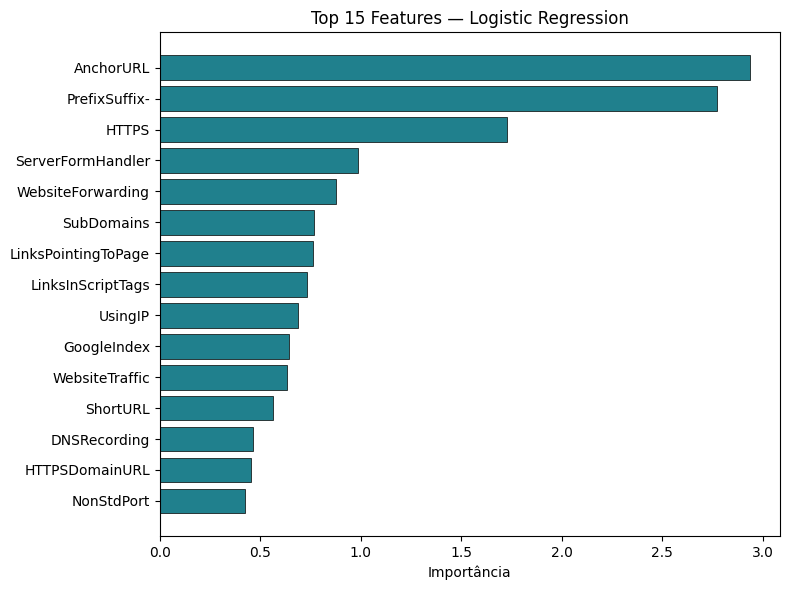


--- TOP 10 — Decision Tree ---
             Feature  Importância
0              HTTPS     0.701949
1          AnchorURL     0.111618
2      PrefixSuffix-     0.054855
3  LinksInScriptTags     0.027144
4         SubDomains     0.023211
5     WebsiteTraffic     0.017522
6  ServerFormHandler     0.011026
7         RequestURL     0.008484
8       DomainRegLen     0.007987
9        AgeofDomain     0.005702


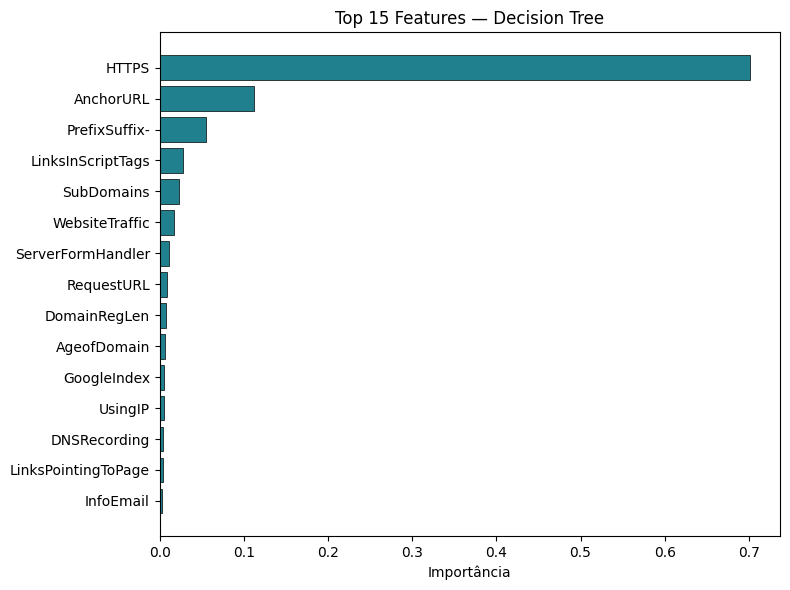


--- TOP 10 — Random Forest ---
               Feature  Importância
0                HTTPS     0.396413
1            AnchorURL     0.261142
2        PrefixSuffix-     0.064661
3           SubDomains     0.063486
4       WebsiteTraffic     0.051230
5    LinksInScriptTags     0.035500
6    ServerFormHandler     0.027868
7           RequestURL     0.014634
8         DomainRegLen     0.010928
9  LinksPointingToPage     0.009285


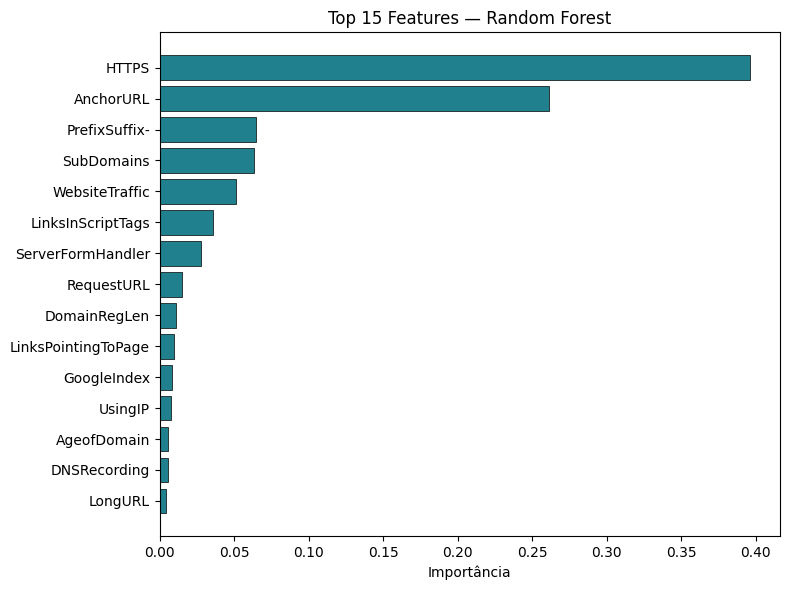


--- TOP 10 — XGBoost ---
             Feature  Importância
0              HTTPS     0.257785
1          AnchorURL     0.195777
2      PrefixSuffix-     0.163324
3  ServerFormHandler     0.029425
4         SubDomains     0.029090
5     WebsiteTraffic     0.027545
6  LinksInScriptTags     0.022638
7        GoogleIndex     0.020802
8           ShortURL     0.019369
9       DNSRecording     0.014880


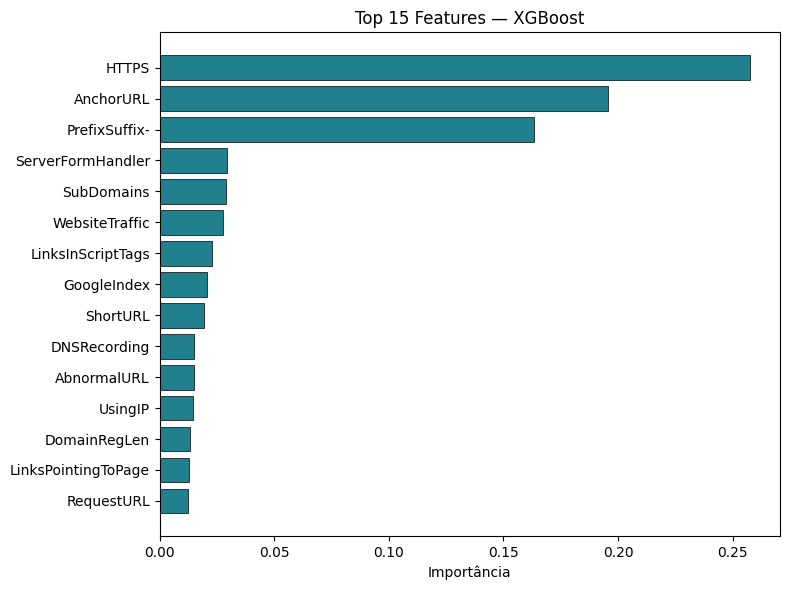

In [11]:
for nome, modelo in modelos:
    importancias = importancia_features(modelo, nomes_features)
    if importancias is not None:
        print(f"\n--- TOP 10 — {nome} ---")
        print(importancias.head(10))
        
        fig = grafico_feature_importance(importancias, nome, top_n=15)
        plt.show()

## 11. Matrizes de confusão

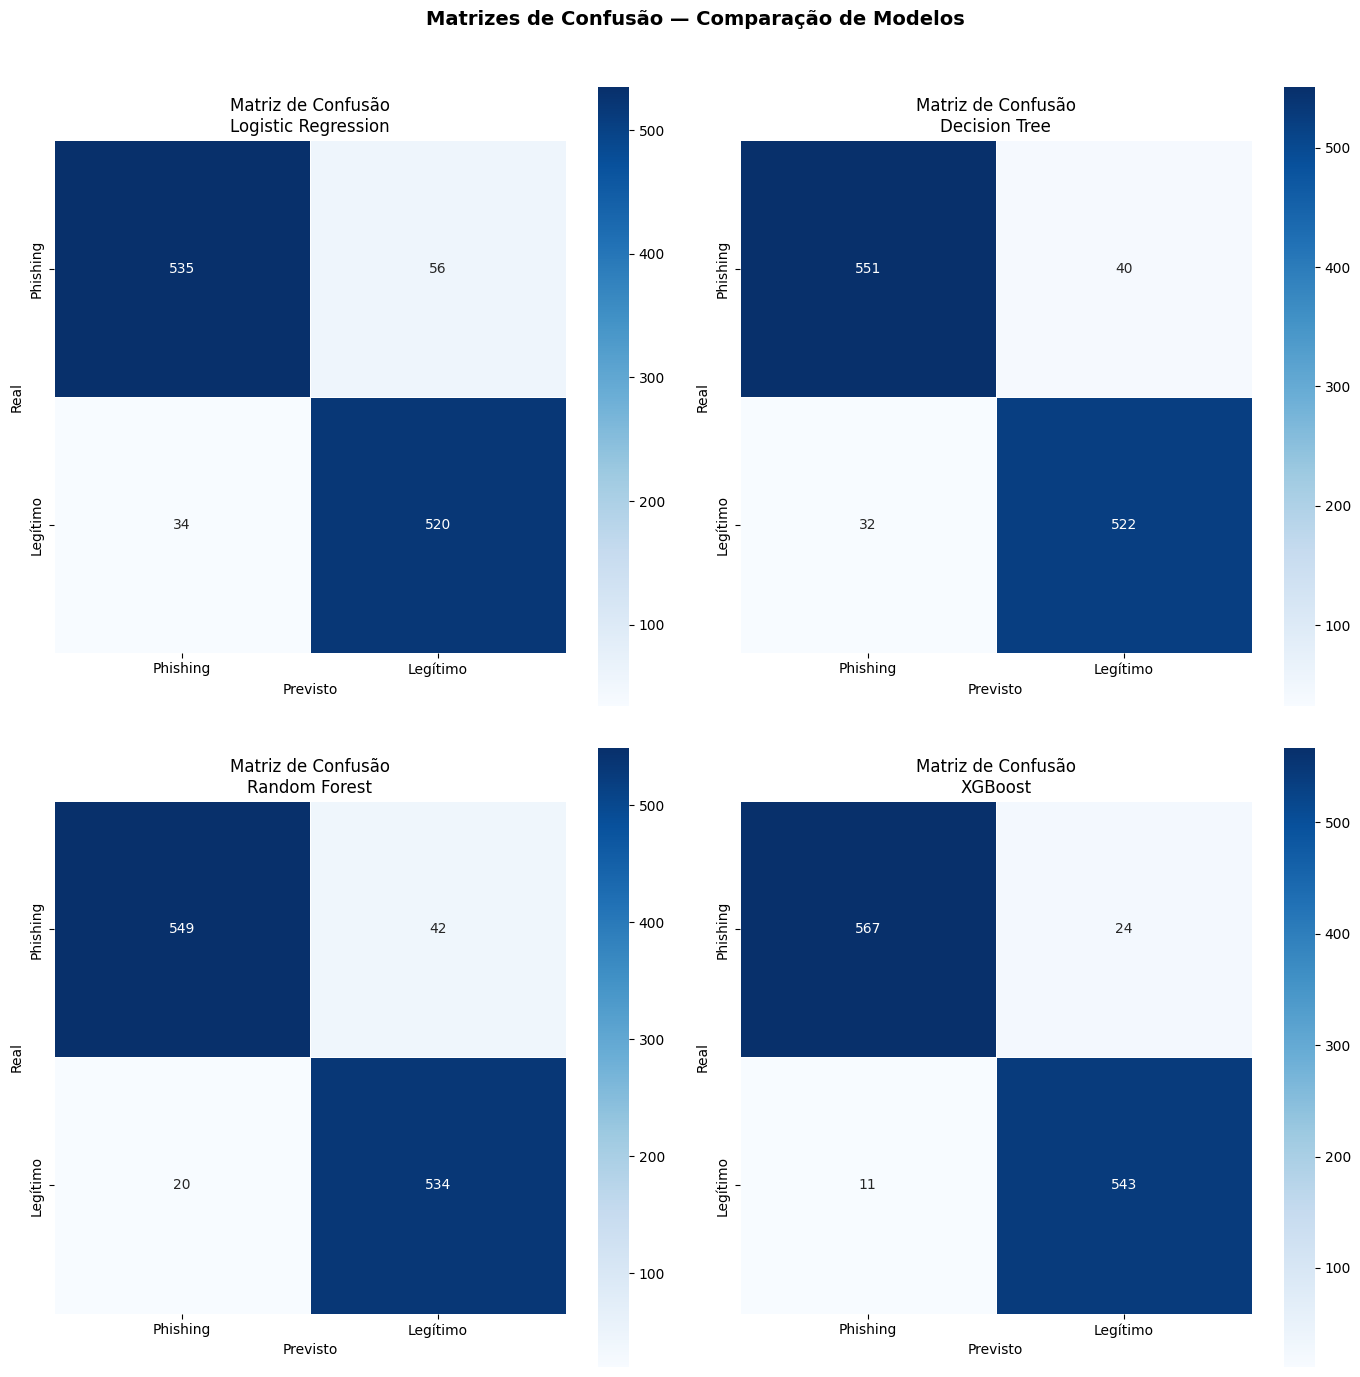

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, resultado in zip(axes.flat, resultados):
    grafico_matriz_confusao(resultado["matriz"], resultado["Modelo"], ax=ax)
plt.suptitle("Matrizes de Confusão — Comparação de Modelos", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3.0)
plt.show()

## 12. Comparação de métricas

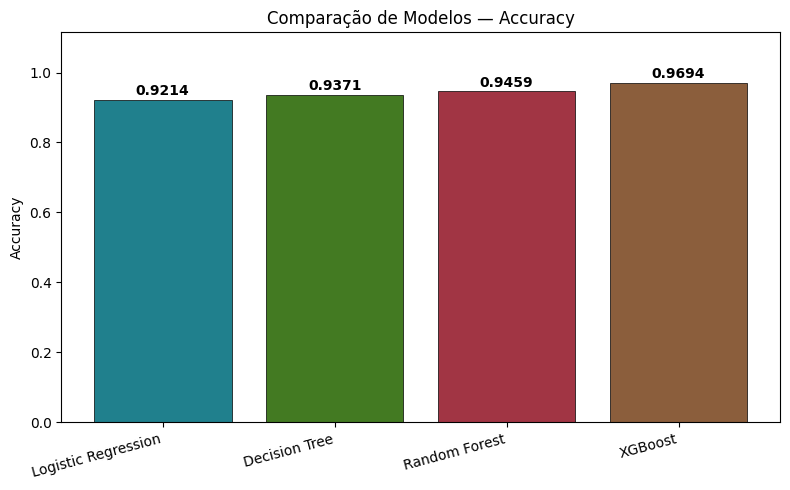

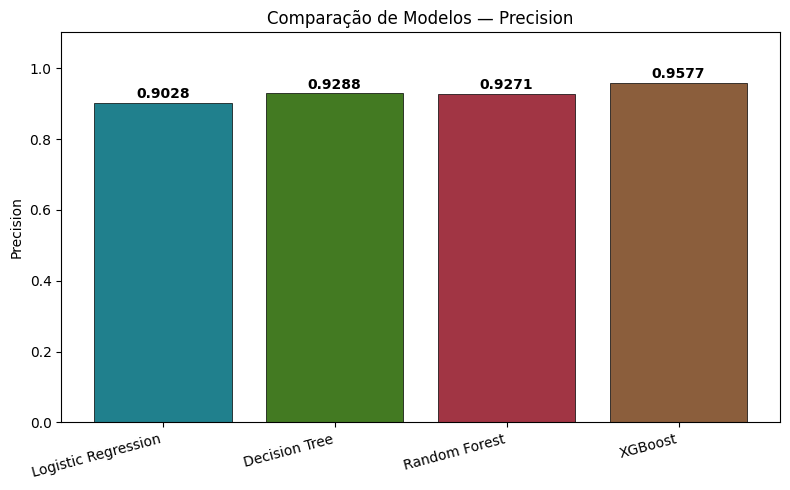

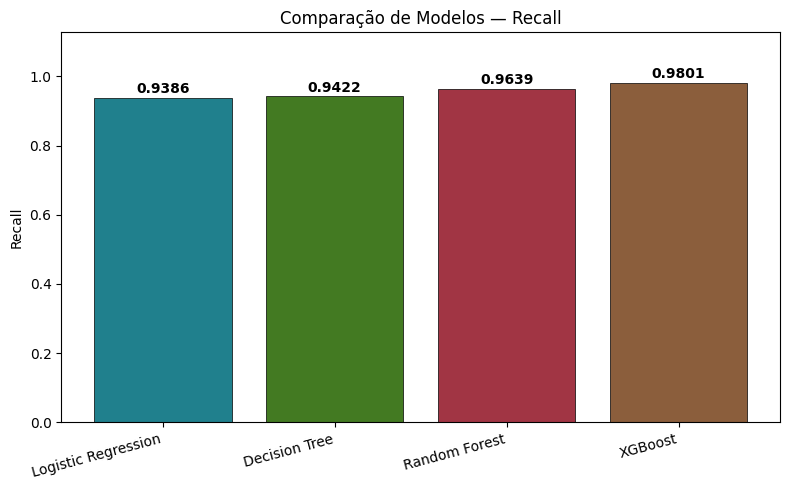

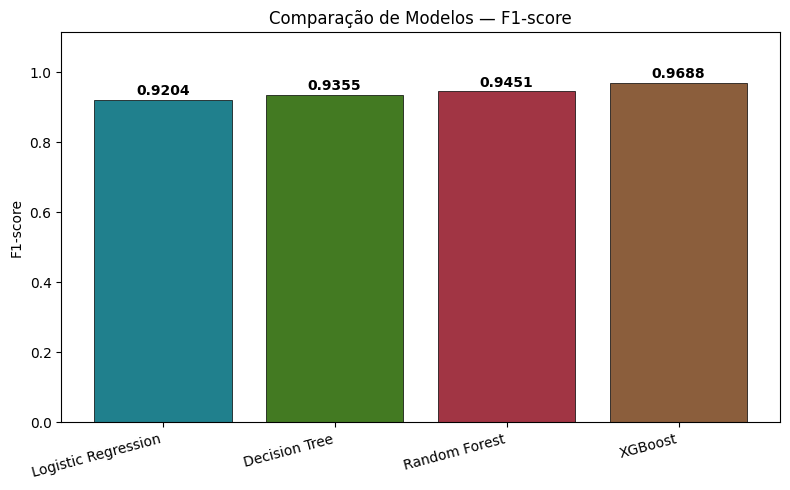

In [13]:
for metrica in ["Accuracy", "Precision", "Recall", "F1-score"]:
    fig = grafico_comparacao(resultados_tabela, metrica=metrica)
    plt.show()

## 13. Curvas ROC

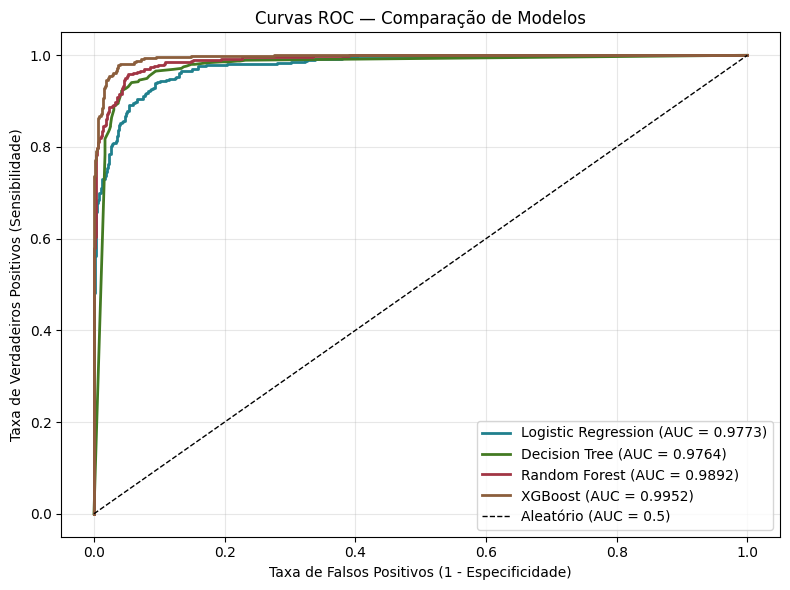

In [14]:
fig = grafico_curvas_roc(resultados, y_test)
plt.show()

## 14. Curvas Precision-Recall

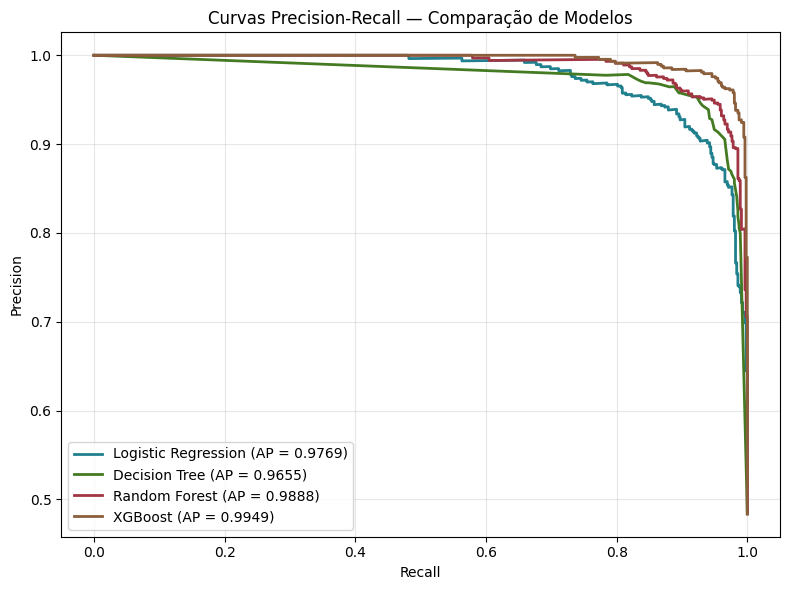

In [15]:
fig = grafico_curvas_pr(resultados, y_test)
plt.show()

## 15. Conclusão

O modelo **XGBoost** demonstrou o melhor desempenho global, com Accuracy de 96,94%, Recall de 98,01% e apenas 11 falsos negativos no conjunto de teste.

As features mais importantes para a deteção de phishing foram **HTTPS**, **AnchorURL** e **PrefixSuffix-**, consistentes em todos os modelos baseados em árvores.

A comparação treino vs teste não revelou overfitting significativo em nenhum dos modelos.

Os próximos passos incluem otimização de hiperparâmetros e avaliação do impacto da remoção de features altamente correlacionadas.